 ## **Exercise 2: Skip-Gram Model**

The Skip-Gram model predicts context words given a target word. For each word in a sequence, it attempts to predict the surrounding words within a specified window size.

### Mathematical Formulation

The Skip-Gram model is designed to learn word embeddings by predicting the context words surrounding a given target word. Intuitively, the model captures semantic relationships between words by maximizing the likelihood of observing the actual context words for each target word in a corpus.

Given a sequence of training words $w_1, w_2, \ldots, w_T$, the Skip-Gram model maximizes the following objective function:

$$
\mathcal{L} = \frac{1}{T} \sum_{t=1}^{T} \sum_{\substack{-c \leq j \leq c \\ j \neq 0}} \log p(w_{t+j} | w_t)
$$

### Intuition Behind the Equation

1. **Objective:**  
   The goal of the Skip-Gram model is to maximize the probability of correctly predicting the context words ($w_{t+j}$) given a target word ($w_t$). The target word acts as an anchor, and the model tries to learn its embedding so that it can effectively represent and predict the context words in its vicinity.

2. **Two Summations:**
   - The **outer summation** over $t$ iterates through all the words in the corpus ($T$ total words).
   - The **inner summation** over $j$ iterates over the context window, considering all words within a fixed range $c$ of the target word $w_t$ (excluding the target word itself, $j \neq 0$). This ensures that the model accounts for multiple context words for each target word.

3. **Normalization Factor $1/T$:**
   Dividing by $T$ ensures that the loss is averaged over the entire corpus, making the training process scale-independent with respect to the corpus size.

### Breaking Down the Probability

The conditional probability $p(w_{t+j} | w_t)$ is modeled using the **softmax function**:

$$
p(w_o | w_i) = \frac{\exp(\mathbf{v}_{w_o}^{\top} \mathbf{v}_{w_i})}{\sum_{w=1}^{|V|} \exp(\mathbf{v}_w^{\top} \mathbf{v}_{w_i})}
$$

Here:
- $\mathbf{v}_{w_i}$ is the **input embedding** of the target word $w_i$.
- $\mathbf{v}_{w_o}$ is the **output embedding** of the context word $w_o$.
- $|V|$ is the vocabulary size, meaning the denominator sums over all words in the vocabulary.

The **dot product** $\mathbf{v}_{w_o}^{\top} \mathbf{v}_{w_i}$ measures the alignment or similarity between the target and context embeddings. The higher the similarity, the higher the conditional probability $p(w_o | w_i)$ after applying softmax.

### Example

Consider the sentence: **"The quick brown fox jumps over the lazy dog"** with a context window size of $c=2$. For the target word "brown," the model predicts its context words:

```python
target_word = "brown"
context = ["The", "quick", "fox", "jumps"]
# The model learns to maximize p(context | target_word)
```

**Task:**
**Task 1: Data Preprocessing**  
Implement `preprocess_corpus(corpus)` to tokenize the text, convert it to sequences of indices, and build the vocabulary.  

**Task 2: Skip-Gram Pairs**  
Write `generate_skipgram_pairs(sequences, window_size)` to generate (target, context) pairs from tokenized sequences.  

**Task 3: Model Architecture**  
- Create `create_skipgram_model(vocab_size, embedding_dim)`.  
- Use `print_model_architecture(model, input_shape)` to display the model summary.

**Task 4: Training**  
Train the model on the provided corpus with window size 2 and embedding dimension 20.

**Task 5: Embedding Visualization**  
Use `plot_word_embeddings(model, tokenizer)` to visualize word embeddings with PCA.

**Task 6: Find Similar Words**  
Implement `find_similar_words(word, tokenizer, model, top_n=3)` to find top-n similar words using cosine similarity.  
Test the function for words: `"cat"`, `"dog"`, `"love"`, `"people"`, `"toy"`, `"the"`.


In [1]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Lambda, Flatten
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


def preprocess_corpus(corpus):
    """
    Tokenize and preprocess the corpus into sequences of word indices.

    Args:
        corpus (list of str): A list of sentences (text corpus), where each sentence is a string.
            Example:
                ["The cat plays with the toy.", "The dog plays with the toy."]

    Returns:
        tokenizer (Tokenizer object imported from tensorflow.keras.preprocessing.text): Fitted tokenizer containing word-index mappings (vocab).
        sequences (list of list of int): A list of tokenized sentences, where each word in a sentence is represented by its index (using vocab word-index mappings).
            Example: [[1, 2, 3, 4, 5], [1, 6, 3, 4, 5]]
        vocab_size (int): The total number of unique words in the corpus, plus one for padding (we add pad token to make all sents have the same size, index 0).

    Example:
        input:    corpus = ["the cat plays with the toy", "The dog plays"]
        output:   Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
                  sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
                  vocab_size: 7
    """
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(corpus)
    sequences = tokenizer.texts_to_sequences(corpus)
    vocab_size = len(tokenizer.word_index) + 1  # +1 for padding token (index 0)
    
    return tokenizer, sequences, vocab_size

# Testing Tokenizer on toy example
example_sents = ["the cat plays with the toy", "The dog plays"]
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)

print("Index to Word:",tokenizer.index_word)
print("Sequences:",sequences)
print("Vocab size:",vocab_size)



Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
Sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
Vocab size: 7


In [2]:
def generate_skipgram_pairs(sequences, window_size=2):
    """
    Generate skip-gram pairs from tokenized sequences using a sliding context window.

    Args:
        sequences (list): A list of tokenized sequences, where each sequence is a list of integers representing words.
            Example: [[1, 2, 3, 4, 5], [6, 7, 8]]
        window_size (int): The size of the context window on each side of the target word (default: 2).
            For example, if window_size=2, the context includes 2 words to the left and 2 words to the right of the target.

    Returns:
        pairs (list of tuple): A list of (target, context) tuples, where each tuple contains a target word and one of its context words.
            Example: [(2, 1), (2, 3), (3, 2), (3, 4), ...]
        x_train (ndarray): An array of target words for training.
            Example: [2, 2, 3, 3, ...]
        y_train (ndarray): An array of context words corresponding to each target word.
            Example: [1, 3, 2, 4, ...]

    Example:
        Input: sequences = [[1, 2, 3, 4]], window_size = 2
        Output: pairs = [(2, 1), (2, 3), (3, 2), (3, 4), (4, 3)]
                x_train = [2, 2, 3, 3, 4]
                y_train = [1, 3, 2, 4, 3]
    """

    pairs = []
    
    for seq in sequences:
        for i, target in enumerate(seq):
            for j in range(max(0, i - window_size), min(len(seq), i + window_size + 1)):
                if i != j:
                    pairs.append((target, seq[j]))
    
    x_train = np.array([p[0] for p in pairs])
    y_train = np.array([p[1] for p in pairs])
    
    return pairs, x_train, y_train





example_sents = [
    "the cat plays with the toy",
    "The dog plays"
]

# Preprocess the corpus
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)
print(sequences)
print(tokenizer.index_word)
# Generate skip-gram pairs
pairs,x_train,y_train = generate_skipgram_pairs(sequences, window_size=2)

# Print detailed information
print("pairs",pairs)
print(x_train )
print(y_train)



[[1, 3, 2, 4, 1, 5], [1, 6, 2]]
{1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
pairs [(1, 3), (1, 2), (3, 1), (3, 2), (3, 4), (2, 1), (2, 3), (2, 4), (2, 1), (4, 3), (4, 2), (4, 1), (4, 5), (1, 2), (1, 4), (1, 5), (5, 4), (5, 1), (1, 6), (1, 2), (6, 1), (6, 2), (2, 1), (2, 6)]
[1 1 3 3 3 2 2 2 2 4 4 4 4 1 1 1 5 5 1 1 6 6 2 2]
[3 2 1 2 4 1 3 4 1 3 2 1 5 2 4 5 4 1 6 2 1 2 1 6]


In [3]:
def create_skipgram_model(vocab_size, embedding_dim):
    """Create Skip-gram model using Sequential API"""

    # Initialize the Sequential model
    model = Sequential([

        # Embedding layer:
        # This layer is used to create word embeddings for the input words.
        # It transforms the input index (which represents a word) into a dense vector representation (embedding).
        # - vocab_size: The size of the vocabulary (number of unique words).
        # - embedding_dim: The dimensionality of the word vectors (e.g., 100, 200).
        # - input_length=1: We are providing a single word as input (length of 1).
        # - name="Word_Embedding": The name for this layer, used for clarity.
        # Embedding(..., name="Word_Embedding"),

        # Flatten layer:
        # This layer flattens the output from the embedding layer, which is a 2D matrix (batch_size, embedding_dim),
        # into a 1D vector. This is necessary before passing the data to a fully connected (Dense) layer.
        # - name="Flatten": The name for this layer, used for clarity.
        # Flatten(name="Flatten"),

        # Dense layer:
        # This layer performs a fully connected operation, mapping the flattened vector to the vocabulary size.
        # The output of this layer is a vector where each value corresponds to the probability of each word in the vocabulary.
        # - vocab_size: The number of output units, which corresponds to the size of the vocabulary.
        # - activation='softmax': Softmax activation ensures the output values are probabilities, summing up to 1.
        # - name="Softmax_Output": The name for this layer, used for clarity.
        # Dense(..., name="Softmax_Output")
        Embedding(vocab_size, embedding_dim, input_length=1, name="Word_Embedding"),
        Flatten(name="Flatten"),
        Dense(vocab_size, activation='softmax', name="Softmax_Output")
    ])

    # Compile the model:
    # - optimizer='adam': Adam optimizer is used for efficient training, especially in cases with sparse gradients.
    # - loss='categorical_crossentropy': Categorical cross-entropy loss function is used for multi-class classification problems.
    # - metrics=['accuracy']: We track accuracy to evaluate the model’s performance during training.
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    # Return the compiled model
    return model

def print_model_architecture(model, input_shape):
    """Print the model architecture (layers, names, and shapes)."""
    # Build the model by providing an example input shape (batch size, sequence length).

    model.build(input_shape)

    # Print model summary to see the details about each layer and its output shapes.
    print("\nModel Architecture:")
    print("=" * 40)
    model.summary()  # This prints out the architecture of the model (layer by layer).
    print("=" * 40)


model = create_skipgram_model(vocab_size, embedding_dim=20)
print_model_architecture(model, input_shape=(None, 1))




Model Architecture:


c:\Users\Rosey\anaconda3\envs\NLP\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Word_Embedding (Embedding)      │ (None, 1, 20)          │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Softmax_Output (Dense)          │ (None, 7)              │           147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 287 (1.12 KB)

 Trainable params: 287 (1.12 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def train_model(model, contexts, targets, epochs=300, batch_size=4):
    """Train the Skip-gram model"""
    early_stopping = EarlyStopping(monitor='loss',
                                 patience=20,
                                 min_delta=0.0001)

    history = model.fit(
        contexts, targets,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=1
    )
    return history

# Model parameters
window_size = 2
embedding_dim = 20

# Create and preprocess corpus
corpus = [
    "the cat plays with toy",
    "the dog plays with toy",
    "the bird plays with toy",
    "the cat eats food",
    "the dog eats food",
    "the bird eats food",
    "people love pets",
    "children like pets",
    "parents love pets",
    "people love animals",
    "children like animals",
    "parents love animals",
    "the cat runs fast",
    "the dog runs fast",
    "the bird flies fast",
    "the cat loves food",
    "the dog loves food",
    "the bird loves food",
    "people like toys",
    "children like toys",
    "parents like toys",
    "people love toys",
    "children love toys",
    "parents love toys",
]
tokenizer, sequences, vocab_size = preprocess_corpus(corpus)

# Generate training data
pairs,x_train,y_train = generate_skipgram_pairs(sequences, window_size)
targets = to_categorical(y_train, num_classes=vocab_size)

# Create and train model
model = create_skipgram_model(vocab_size, embedding_dim)

# Print model architecture
print_model_architecture(model, input_shape=(None, 1))

# Train the model
history = train_model(model, x_train, targets, epochs=200, batch_size=8)




Model Architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Word_Embedding (Embedding)      │ (None, 1, 20)          │           440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Softmax_Output (Dense)          │ (None, 22)             │           462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 902 (3.52 KB)

 Trainable params: 902 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0735 - loss: 3.0857   
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1373 - loss: 3.0676     
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2059 - loss: 3.0502 
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2353 - loss: 3.0317 
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2549 - loss: 3.0104 
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2647 - loss: 2.9867 
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2794 - loss: 2.9596 
Epoch 8/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2745 - loss: 2.9285 
Epoch 9/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2745 - loss: 2.8939 
Epoch 10/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2843 - loss: 2.8555 
Epoch 11/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2843 - loss: 2.8135
Epoch 12/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/

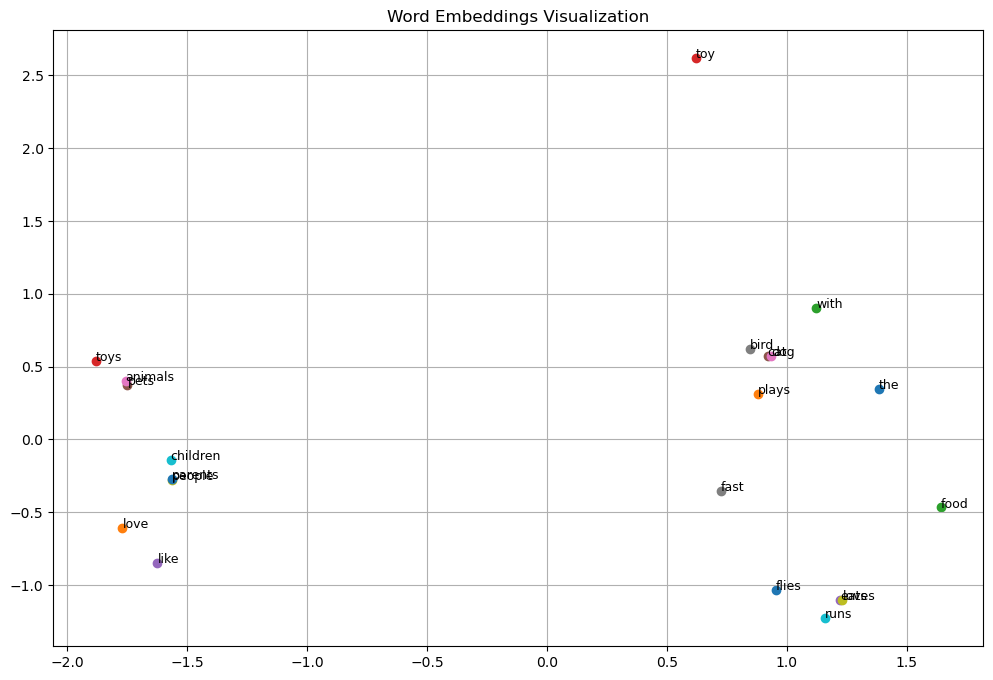

[('cat', 0.99999994), ('dog', 0.9981898), ('bird', 0.8620982)]
[('dog', 1.0), ('cat', 0.9981898), ('bird', 0.8554597)]
[('love', 1.0), ('like', 0.83272815), ('people', 0.34666878)]
[('people', 1.0000001), ('parents', 0.998203), ('children', 0.87338763)]
[('toy', 0.9999999), ('with', 0.41619164), ('bird', 0.37047645)]
[('the', 0.9999998), ('food', 0.77752185), ('fast', 0.68249714)]


In [5]:
def get_word_vector(word, tokenizer, model):
    """
    Get embedding vector for a word.

    The goal of this function is to retrieve the embedding vector of a given word from the trained Skip-gram model.
    The function uses the tokenizer to look up the word index and fetch the corresponding embedding vector from the model.

    Input:
        - word (str): The word for which we want to retrieve the embedding vector.
        - tokenizer (keras.preprocessing.text.Tokenizer): The tokenizer used during model training. It provides the word index.
        - model (keras.models.Sequential): The trained Skip-gram model that contains the word embedding layer.

    Output:
        - (numpy.ndarray or None): The embedding vector of the word as a numpy array if the word is in the vocabulary.
          Returns `None` if the word is not found in the tokenizer's word index.

    Hint: use model.get_layer('layername').get_weights()[0] to get the weights of a given layer

    Example:
        - Input: word="king", tokenizer=tokenizer_object, model=model_object
        - Output: array([0.123, 0.456, ..., -0.789])  # The embedding vector of "king"

    If the word is not found:
        - Input: word="unknown_word", tokenizer=tokenizer_object, model=model_object
        - Output: None
    """
    # your code here
    if word not in tokenizer.word_index:
        return None
    word_idx = tokenizer.word_index[word]       
    embedding_matrix = model.get_layer('Word_Embedding').get_weights()[0]
    word_vector = embedding_matrix[word_idx]
    return word_vector


def find_similar_words(word, tokenizer, model, top_n=3):
    """
    Find most similar words using cosine similarity.

    The goal of this function is to find the most similar words to the input word based on cosine similarity of their
    embedding vectors. It computes the cosine similarity between the embedding vector of the input word and all the
    other word embeddings in the model's vocabulary and returns the top_n most similar words.

    Input:
        - word (str): The word for which we want to find similar words.
        - tokenizer (keras.preprocessing.text.Tokenizer): The tokenizer used during model training. It provides the word index and index_word mapping.
        - model (keras.models.Sequential): The trained Skip-gram model with the word embeddings.
        - top_n (int, optional): The number of most similar words to return (default is 3).

    Output:
        - (list of tuples): A list of tuples, each containing a word and its similarity score.
          The list is sorted in descending order of similarity, and the length of the list is at most `top_n`.
          Each tuple is of the form (word, similarity).

    Example:
        - Input: word="king", tokenizer=tokenizer_object, model=model_object, top_n=3
        - Output:
          [("queen", 0.89),
           ("prince", 0.75),
           ("monarch", 0.72)]

    If the word is not in the vocabulary:
        - Input: word="unknown_word", tokenizer=tokenizer_object, model=model_object, top_n=3
        - Output: []
    """
    word_vector = get_word_vector(word, tokenizer, model)
    if word_vector is None:
        return []

    embedding_matrix = model.get_layer('Word_Embedding').get_weights()[0]
    similarities = cosine_similarity([word_vector], embedding_matrix)[0]

    similar_words = []
    for i in range(1, len(tokenizer.word_index) + 1):
        similar_words.append((tokenizer.index_word[i], similarities[i]))

    similar_words.sort(key=lambda x: x[1], reverse=True)

    return similar_words[:top_n]


def plot_word_embeddings(model, tokenizer):
    """Visualize word embeddings using PCA"""

    # Get the embedding weights from the model's 'Word_Embedding' layer
    # model.get_layer('Word_Embedding').get_weights()[0] returns the weight matrix of the embedding layer
    # This matrix has a shape of (vocab_size, embedding_dim), where each row is a word's embedding.
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]

    # Apply PCA (Principal Component Analysis) to reduce the dimensionality of the embeddings
    # from high-dimensional space (e.g., 100 dimensions) to 2 dimensions for visualization.
    pca = PCA(n_components=2)  # We want to reduce the embeddings to 2D for plotting
    reduced_embeddings = pca.fit_transform(embeddings)  # Fit the PCA model and transform the embeddings to 2D

    # Create a plot to visualize the 2D word embeddings
    plt.figure(figsize=(12, 8))  # Set the figure size for the plot

    # Loop through the vocabulary and plot each word's reduced embedding (2D coordinates)
    for i in range(1, len(tokenizer.word_index) + 1):
        word = tokenizer.index_word[i]  # Get the word from the index
        x, y = reduced_embeddings[i]  # Get the 2D coordinates of the word's embedding

        # Plot the word's embedding as a scatter point
        plt.scatter(x, y)

        # Annotate the scatter point with the word (placing the word label at the coordinates)
        plt.annotate(word, (x, y), fontsize=9)

    # Set the title for the plot
    plt.title("Word Embeddings Visualization")

    # Enable the grid for better visibility of the plot
    plt.grid(True)

    # Show the plot
    plt.show()


plot_word_embeddings(model, tokenizer)


print(find_similar_words("cat", tokenizer, model, top_n=3))
print(find_similar_words("dog", tokenizer, model, top_n=3))
print(find_similar_words("love", tokenizer, model, top_n=3))
print(find_similar_words("people", tokenizer, model, top_n=3))
print(find_similar_words("toy", tokenizer, model, top_n=3))
print(find_similar_words("the", tokenizer, model, top_n=3))